# Curation

In this tutorial we will view and curate spike sorting results. We will first do some manual curation with the SpikeInterface-GUI, then show some automated tools for unit labeling and merging.

In [1]:
import json
import warnings
from pathlib import Path

import spikeinterface.full as si


In [2]:
warnings.filterwarnings("ignore")

In [3]:
%matplotlib widget

In [4]:
si.set_global_job_kwargs(n_jobs=0.5)

In [5]:
# change this path to point to the folder your data is in
home = Path.home()
base_data_folder = Path(home / "cnn_2026")

data_folder = base_data_folder / "data"
name = "sub-A3702_ses-191126-3600s"
result_folder = base_data_folder / "results" / name
result_folder.mkdir(exist_ok=True, parents=True)


In [6]:
# sorter_name = "lupin"
# sorter_name = "kilosort4"
sorter_name = "dartsort"

analyzer_folder = result_folder / f"analyzer_{sorter_name}"

analyzer = si.load(analyzer_folder)
analyzer

SortingAnalyzer: 64 channels - 393 units - 1 segments - binary_folder - sparse
Loaded 11 extensions: templates, noise_levels, random_spikes, spike_amplitudes, unit_locations, waveforms, template_similarity, correlograms, template_metrics, spike_locations, quality_metrics

In [18]:
# copy analyzer to a new folder 
analyzer = analyzer.save_as(
    folder=result_folder / f"analyzer_{sorter_name}_with_labels",
    format="binary_folder",
)
analyzer

SortingAnalyzer: 64 channels - 393 units - 1 segments - binary_folder - sparse
Loaded 11 extensions: random_spikes, waveforms, templates, noise_levels, spike_amplitudes, unit_locations, template_similarity, correlograms, template_metrics, spike_locations, quality_metrics

## Automatic curation tools

### Threshold-based curation

This strategy for curation uses different thresholds on quality metrics. Quality metrics are designed to quantify different aspects of a unit, such as amplitude, SNR, drift, ISI violations, spike train completeness, and more.

A ful list of available quality metrics is available [here](https://spikeinterface.readthedocs.io/en/latest/modules/qualitymetrics.html).

In [19]:
qm = analyzer.get_extension("quality_metrics").get_data()
print(f"Available metrics: {qm.columns.values.to_numpy()}")

Available metrics: ['num_spikes' 'firing_rate' 'presence_ratio' 'snr' 'isi_violations_ratio'
 'isi_violations_count' 'rp_contamination' 'rp_violations'
 'sliding_rp_violation' 'sync_spike_2' 'sync_spike_4' 'sync_spike_8'
 'firing_range' 'amplitude_cv_median' 'amplitude_cv_range'
 'amplitude_cutoff' 'noise_cutoff' 'noise_ratio' 'amplitude_median'
 'drift_ptp' 'drift_std' 'drift_mad' 'sd_ratio']


`qm` is a `pandas.DataFrame` with unit ID as indices. We can easily perform a query with a quality-metric "recipe", such as:

In [20]:
qm.head()

,num_spikes,firing_rate,presence_ratio,snr,isi_violations_ratio,isi_violations_count,rp_contamination,rp_violations,sliding_rp_violation,sync_spike_2,...,amplitude_cv_median,amplitude_cv_range,amplitude_cutoff,noise_cutoff,noise_ratio,amplitude_median,drift_ptp,drift_std,drift_mad,sd_ratio
0,780,0.216667,0.433333,2.352651,386.587771,196,1.00000,147,NaN,0.255128,...,NaN,NaN,0.0,0.170451,0.030510,-16.493656,NaN,NaN,NaN,4.122605
1,3835,1.065278,0.800000,6.740119,14.768252,181,1.00000,94,NaN,0.233638,...,NaN,NaN,0.0,-0.327068,0.021275,-36.250774,NaN,NaN,NaN,2.654834
2,1574,0.437222,0.783333,5.725229,63.936038,132,1.00000,108,NaN,0.245870,...,0.584658,1.003920,0.0,0.042657,0.040333,-32.338390,NaN,NaN,NaN,3.573449
3,46,0.012778,0.050000,13.595198,15879.017013,28,1.00000,27,NaN,0.239130,...,NaN,NaN,NaN,0.184762,0.088889,-61.533329,NaN,NaN,NaN,25.129154
4,1956,0.543333,1.000000,3.827824,0.313649,1,0.75699,1,NaN,0.247444,...,0.616275,0.813362,0.0,0.192793,0.063899,20.984222,NaN,NaN,NaN,3.350523


In [21]:
si.threshold_metrics_label_units?

Signature:
si.threshold_metrics_label_units(
    metrics: 'pd.DataFrame',
    thresholds: dict | str | pathlib.Path,
    pass_label: str = 'good',
    fail_label: str = 'noise',
    operator: str = 'and',
    nan_policy: str = 'fail',
    column_name: str = 'label',
)
Docstring:
Label units based on metrics and thresholds.

Parameters
----------
metrics : pd.DataFrame
    A DataFrame containing unit metrics with unit IDs as index.
thresholds : dict | str | Path
    A dictionary or JSON file path where keys are metric names and values are threshold values for labeling units.
    Each key should correspond to a quality metric present in the analyzer's quality metrics DataFrame. Values
    should contain at least "greater" and/or "less" keys to specify threshold ranges. Thresholds are inclusive, i.e.
    "greater" is >= and "less" is <=. Optionally, an "abs": True entry can be included to indicate that the metric
    should be treated as an absolute value when applying thresholds.
pass_la

In [22]:
qc_thresholds = {
    "rp_contamination": {"less": 0.5},
    "presence_ratio": {"greater": 0.8},
    "amplitude_cutoff": {"less": 0.1}
}

In [23]:
threshold_df = si.threshold_metrics_label_units(qm, thresholds=qc_thresholds, column_name="threshold_label")
threshold_df

,threshold_label
0,noise
1,noise
2,noise
3,noise
4,noise
...,...
388,noise
389,good
390,good
391,good


In [24]:
threshold_df["threshold_label"].value_counts()

threshold_label
noise    333
good      60
Name: count, dtype: int64

Let's see how they look! The `SortingAnalyzer` has a convenient function to select units and propagate all extensions:

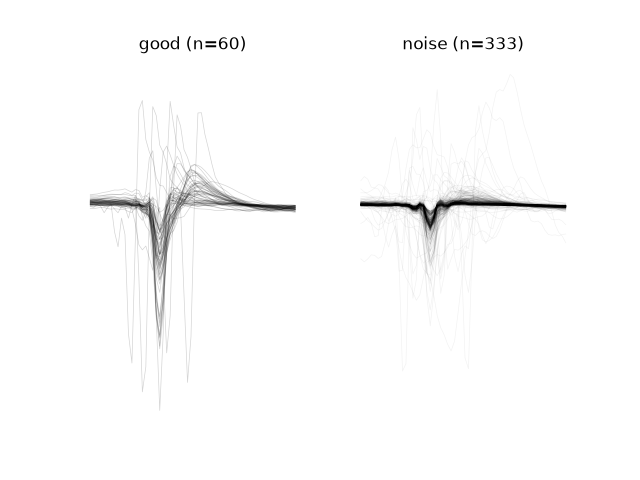

In [25]:
w = si.plot_unit_labels(analyzer, threshold_df["threshold_label"])

**NICE!!** Most of noisy units are gone, but there are also potential good units in the noise group... maybe our curation was too strict?

### Automatic labeling

In the `curation` module we also provide some model-based automatic labeling of units. 

There are two auti-labeling tools:

* **UnitRefine**: uses pre-trained classifiers from hand-curated data from the [UnitRefine](https://www.biorxiv.org/content/10.1101/2025.03.30.645770v1) project. UniteRefine models use quality and template metrics to classify units as being `noise` or `neural` and `SUA` (single-unit activity) or `MUA` (multi-unit activity). All available models are publicly available on the [SpikeInterface HuggingFace Organization](https://huggingface.co/SpikeInterface).

* **BombCell**: uses a set of advanced heuristics based on quality and template metrics. For more information, see the [Bombcell repo](https://github.com/Julie-Fabre/bombcell)

Let's see how to use them!

For example, for the Bombcell pipeline
![image](images/bombcell_flowchart.png)

In [26]:
unitrefine_df = si.unitrefine_label_units(
    analyzer,
    noise_neural_classifier="SpikeInterface/UnitRefine_noise_neural_classifier_lightweight",
    sua_mua_classifier="SpikeInterface/UnitRefine_sua_mua_classifier_lightweight",
)

In [27]:
unitrefine_df["unitrefine_label"].value_counts()

unitrefine_label
mua      233
noise    113
sua       47
Name: count, dtype: int64

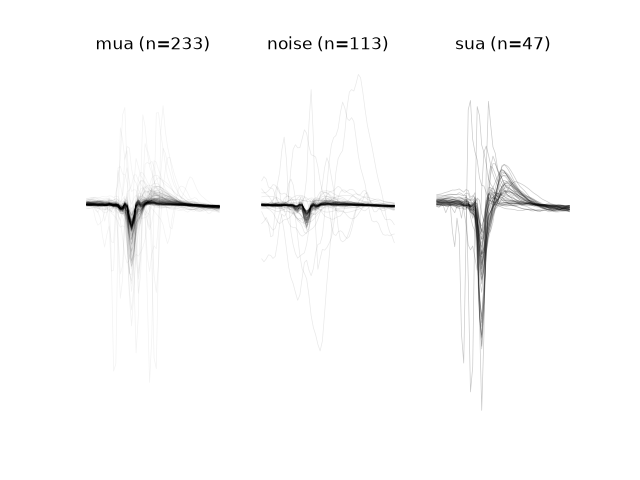

In [28]:
w = si.plot_unit_labels(analyzer, unitrefine_df["unitrefine_label"])

In [29]:
si.bombcell_label_units?

Signature:
si.bombcell_label_units(
    sorting_analyzer=None,
    thresholds: dict | str | pathlib.Path | None = None,
    split_non_somatic: bool = False,
    external_metrics: 'pd.DataFrame | list[pd.DataFrame] | None' = None,
    label_non_somatic: bool | None = None,
    split_non_somatic_good_mua: bool | None = None,
) -> 'pd.DataFrame'
Docstring:
Label units based on quality metrics and template metrics using Bombcell logic:

1. NOISE:
    Units that fail any of the noise thresholds are labeled as "noise". The thresholds in the "noise" section
    are applied with an "AND" operator, meaning a unit must fail at least one noise metric to be labeled as
    "noise". Units that are not labeled as "noise" are then evaluated for MUA thresholds.
2. MUA:
    Units that are not "noise" but fail any of the MUA thresholds are labeled as "mua". The thresholds in the
    "mua" section are also applied with an "AND" operator, meaning a unit must fail at least one MUA metric to
    be labeled a

In [30]:
bombcell_thresholds = si.bombcell_get_default_thresholds()
bombcell_thresholds

{'noise': {'num_positive_peaks': {'greater': None, 'less': 2},
  'num_negative_peaks': {'greater': None, 'less': 1},
  'peak_to_trough_duration': {'greater': 0.0001, 'less': 0.00115},
  'waveform_baseline_flatness': {'greater': None, 'less': 0.5},
  'peak_after_to_trough_ratio': {'greater': None, 'less': 0.8},
  'exp_decay': {'greater': 0.01, 'less': 0.1}},
 'mua': {'amplitude_median': {'greater': 30, 'less': None, 'abs': True},
  'snr': {'greater': 5, 'less': None},
  'amplitude_cutoff': {'greater': None, 'less': 0.2},
  'num_spikes': {'greater': 300, 'less': None},
  'sliding_rp_violation': {'greater': None, 'less': 0.1},
  'presence_ratio': {'greater': 0.7, 'less': None},
  'drift_ptp': {'greater': None, 'less': 100},
  'isolation_distance': {'greater': 20, 'less': None},
  'l_ratio': {'greater': None, 'less': 0.3}},
 'non-somatic': {'peak_before_to_trough_ratio': {'greater': None, 'less': 3},
  'peak_before_width': {'greater': 0.00015, 'less': None},
  'trough_width': {'greater': 0

In [31]:
bombcell_df = si.bombcell_label_units(
    analyzer,
    thresholds=bombcell_thresholds
)
bombcell_df

,bombcell_label
0,noise
1,mua
2,mua
3,mua
4,noise
...,...
388,mua
389,mua
390,mua
391,good


In [32]:
bombcell_df["bombcell_label"].value_counts()

bombcell_label
mua         299
noise        75
good         15
non_soma      4
Name: count, dtype: int64

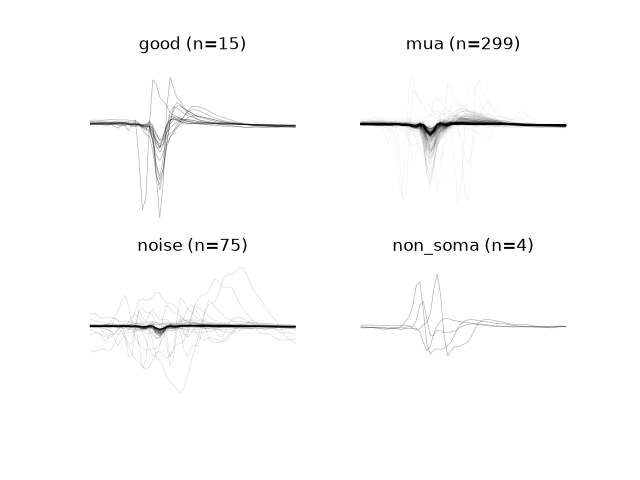

In [33]:
w = si.plot_unit_labels(analyzer, bombcell_df["bombcell_label"])

In [34]:
# it is also convenient to store the labels in the sorting analyzer, so we can show them later in the GUI
analyzer.set_sorting_property("threshold_label", threshold_df["threshold_label"].to_numpy(dtype=str))
analyzer.set_sorting_property("unitrefine_label", unitrefine_df["unitrefine_label"].to_numpy(dtype=str))
analyzer.set_sorting_property("bombcell_label", bombcell_df["bombcell_label"].to_numpy(dtype=str))

### Auto-merging

Both quality metric-based and model-based curation provide labels for individual units. A common spike sorting mistake, however, is to *oversplit* units, i.e., multiple sorted units are actually from the same underlying neuron.

These errors are usually manually fixed with curation, but the curation module also provides some automated strategies to find potential merges. These strategies have different flavors, but usually use the similarity across templates and auto/cross correlogram shapes to make a merge decision.

See [compute_merge_unit_groups](https://spikeinterface.readthedocs.io/en/latest/api.html#spikeinterface.curation.compute_merge_unit_groups) function for documentation.

In this case, we are going to use the [SLAy](https://www.biorxiv.org/content/10.1101/2025.06.20.660590v3) method. 

![image](images/slay.png)

In [35]:
potential_merges = si.compute_merge_unit_groups(
    analyzer,
    preset="slay",
    steps_params={"template_similarity": {"template_diff_thresh": 0.5}}
)

In [36]:
print(f"Found {len(potential_merges)} potential merges")
print(f"First potential merge: {potential_merges[0]}")

Found 5 potential merges
First potential merge: [np.int64(13), np.int64(20)]


In [37]:
si.plot_potential_merges(analyzer, potential_merges, backend='ipywidgets')

Ignoring fixed x limits to fulfill fixed data aspect with adjustable data limits.
Ignoring fixed x limits to fulfill fixed data aspect with adjustable data limits.


AppLayout(children=(VBox(children=(Label(value='Potential merges:'), Dropdown(layout=Layout(width='80%'), opti…

In [38]:
si.compute_merge_unit_groups?

Signature:
si.compute_merge_unit_groups(
    sorting_analyzer: spikeinterface.core.sortinganalyzer.SortingAnalyzer,
    preset: str | None = 'similarity_correlograms',
    resolve_graph: bool = True,
    steps_params: dict = None,
    compute_needed_extensions: bool = True,
    extra_outputs: bool = False,
    steps: list[str] | None = None,
    force_copy: bool = True,
    **job_kwargs,
) -> Union[list[tuple[int | str, int | str]], Tuple[list[tuple[int | str, int | str]], dict]]
Docstring:
Algorithm to find and check potential merges between units.

The merges are proposed based on a series of steps with different criteria:

    * "num_spikes": enough spikes are found in each unit for computing the correlogram (`min_spikes`)
    * "snr": the SNR of the units is above a threshold (`min_snr`)
    * "remove_contaminated": each unit is not contaminated (by checking auto-correlogram - `contamination_thresh`)
    * "unit_locations": estimated unit locations are close enough (`max_distance_u